<a target="_blank" href="https://colab.research.google.com/github/taobrienlbl/advanced_earth_science_data_analysis/blob/fall_2025_iub/content/lessons/02_modules_vscode_git/02_last_class_refresher.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Warmup: fundamentals

Recall that last week's objectives were:

* Describe fundamental aspects of a working Python script
* Implement novel functions and for loops along with appropriate unit tests
* Utilize 'external' python packages

This warm-up aims to build on those objectives and reinforce them.


## 1. Basics of functions

### 1(a): ins and outs

Run the following cell.  It doesn't work as expected.  Explain why (in a markdown cell below it) and create a new cell below that with a fixed version of the code.

In [1]:
def factorial(n):
    """Calculates the factorial of a number."""
    fac = 1
    if n == 1:
        fac = 1
    else:
        fac = n * factorial(n-1)


# test the factorial function; this should print 120
print(factorial(5))

TypeError: unsupported operand type(s) for *: 'int' and 'NoneType'

Based on the error messages I am seeing, I believe the code is not running properly because the function (fac) is set to calculate, but there is no actual calculation set up for it to return any value. This is because in Python code, a function that has no return statements will just return nothing. As we can see, factorial(1) returns nothing, which therefore causes an error in the next step because it is trying to multiply with nothing. I believe the best way and easiest way to fix this code is to get a return value from the factorial function!

In [2]:
def factorial(n):
    """Calculates the factorial of a number."""
    if n == 1:
        return 1
    else:
        return n * factorial(n-1)

# test the factorial function; this should print 120
print(factorial(5))

120


### 1(b): Writing new functions

Write a function representing the formula $z = x^2 + y^2$ and verify that it works as expected.

In [3]:
def z(x, y): # this enables me to define the function for z which takes values from x and y
    return x**2 + y**2 # this is the Python version of the above equation since Python uses ** to define an exponent

print(z(3, 4)) # based on the x and y values the math should work out to 25!

25


### 1(c): Scope

We haven't yet discussed the concept of *scope*, so we'll introduce it here through examining an interesting effect (and we'll discuss it more as time goes on.)

Run the cell below.  We see that the value of `a` is redefined when `redefine_and_print_a()` is called, so why does the last print statement contain the original definition of `a` and not the one it was given within the function?


In [4]:
# define a as a global variable here
a = "This is `a` with global scope."
# print a to show its value
print(f"1: {a}")

# define a function
def redefine_and_print_a():
    # define a as a local variable here
    a = "This is `a` with local scope."
    # print a to show its value
    print(f"2: {a}")

# call the function
redefine_and_print_a()

# print a one more time to show its value
print(f"3: {a}")

1: This is `a` with global scope.
2: This is `a` with local scope.
3: This is `a` with global scope.


The reason that the last print statement contains the original definition of a and not the one it was given within the function is because the value of a that was inside the function only exists within the function's local scope. As changing a inside the fuction does not actually change the original globe value of a outside of the function. So therefore, in the final printed statement, it is still able to use its original definition.

## 2. Using external packages

Make a plot of the following equation  using `numpy` and `matplotlib`.  Use `x` values ranging from -8 to 8, and make plots using the following values of $\sigma$: $\sigma = [0.25,0.5,1,2,4]$

$$N(x) = \frac{1}{\sigma \sqrt{2 \pi}} e^{-\frac{x^2}{2 \sigma^2}}$$

Your solution should (a) define a new function to represent this formula, and (b) use a `for` loop.

If you have time, customize the x- and y-axis labels, and add a legend.

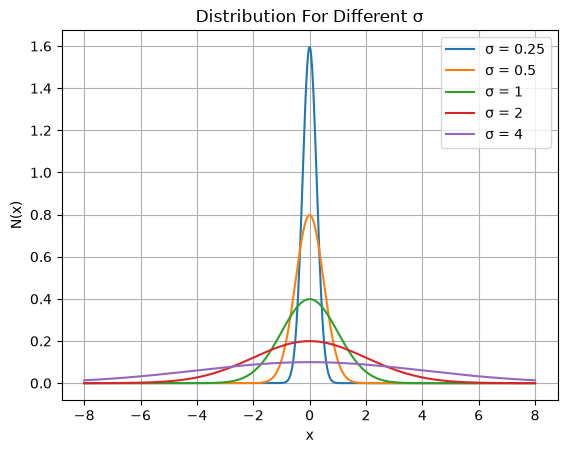

In [5]:
import numpy as np # we need numpy library to import values and calculate 
import matplotlib.pyplot as plt # this library is needed to actually create the graph

def distribution(x, sigma): # this the function for the distribution where x are the x-value and sigma is the standard deviation
    return (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-(x**2) / (2 * sigma**2)) # the python version of the above equation

x = np.linspace (-8, 8, 1000) # using this helpful because it will give 1000 even spaces for our range [-8, 8]
sigmas = [0.25, 0.50, 1, 2, 4] # small sigma should be narrow and large sigma should be wide

for s in sigmas: # this enables the loop through each sigma value I defined
    plt.plot(x, distribution(x, s), label=f"σ = {s}") # this enables what actually gets plotted
    
plt.xlabel("x") # horizontal axis
plt.ylabel("N(x)") # value of the normal distribution
plt.title("Distribution For Different σ") # title
plt.legend() # so we know what each curve and its value
plt.grid(True) # makes it easier to read in my opinion
plt.show() # displays the graph